# Creating the dataset

In [1]:
# Parameters
LENGTH = 40
SAMPLING_FREQUENCY = 10
NOISE = 0.1
WINDOW_SIZE = 64

Generate a synthetic dataset:

In [2]:
from make_dataset import generate_signal

# Generate the dataset
signal = generate_signal(LENGTH, SAMPLING_FREQUENCY, NOISE)
time, value = signal["time"], signal["value"]

Introduce some anomalies (*i.e.* spikes) to the dataset:

In [3]:
import numpy as np

# Add a few spikes to the signal in random locations
NUM_ANOMALIES = 5
anom_idx = np.random.choice(range(WINDOW_SIZE, len(value)), size=NUM_ANOMALIES, replace=False)
anom_idx.sort()
value[anom_idx] += np.random.choice([-1, 1], size=NUM_ANOMALIES) * 0.5

Plot the generated signal with the added anomalies:

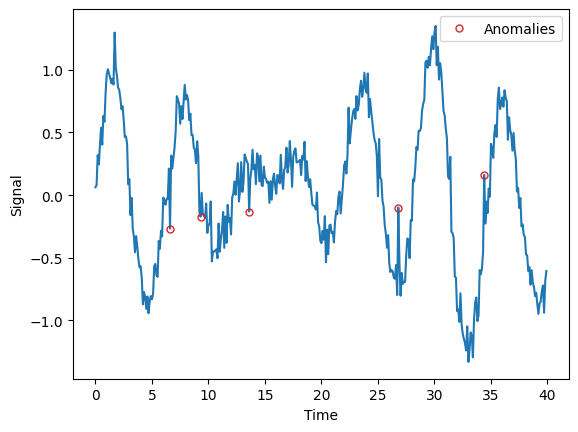

In [4]:
import matplotlib.pyplot as plt

plt.plot(time, value)
plt.plot(time[anom_idx], value[anom_idx], marker='o', mfc='none', ms=5, linestyle='none', c='tab:red', label='Anomalies')
plt.xlabel("Time")
plt.ylabel("Signal")
plt.legend()
plt.show()

# TSM pipeline

The following will be performed in C++ in the main TSM POZ app, either in pure C++ or by calling Python classes from the code.

Instantiate the algorithm, which loads a pre-trained LSTM model (see `lstm_training.ipynb` for more information) :

In [5]:
from algorithm import DummyLSTMAnomalyDetection

# Instantiate the algorithm, which loads a Keras LSTM model
synchronized_detection = DummyLSTMAnomalyDetection("config.json")

# Algorithm setup (i.e. model loading)
synchronized_detection.setup()

I0000 00:00:1783511610.189433   57764 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1783511611.807682   57764 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1783511613.825057   57764 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1783511614.881608   57764 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1783511614.934960   57764 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at htt

The algorithm runs on a sliding window, using the past `WINDOW_SIZE=64` points to predict the next one. We wait until 65 points are generated to compare the 65th "measured" one with the one predicted by the model and return a boolean (*i.e.* `True`: anomaly, `False`: normal).

We repeat this every time a new point is "generated", by sliding the window one point to the right and calling the `run` method again:

In [6]:
from make_dataset import to_windowed_payloads
from tsmadkit.signals import SignalSet

# List to keep track of the successive boolean labels
anomalous = []

# Run the anomaly detection algorithm for every successive window and save the label
for payload in to_windowed_payloads(signal, "sensor_0", synchronized_detection.window_size + 1):
    data = SignalSet(payload, synchronized_detection.signal_spec)
    result = synchronized_detection.detect(data)
    anomalous.append(result.is_anomaly)

I0000 00:00:1783511623.315279   57930 service.cc:153] XLA service 0x7ac244033f60 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783511623.315342   57930 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1783511623.345517   57930 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1783511623.650596   57930 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Plot the signal with the actual anomalies and the predicted ones:

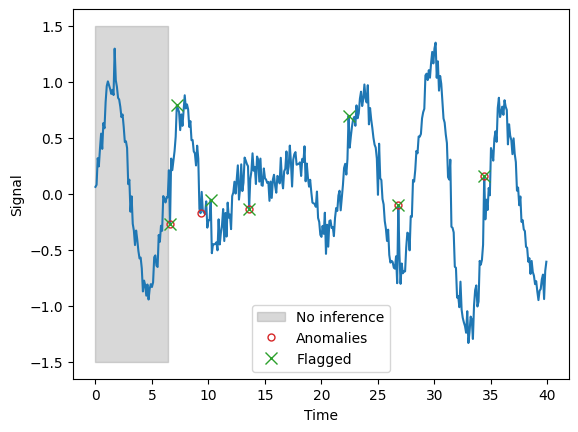

In [7]:
plt.plot(time, value)
plt.fill_betweenx([-1.5, 1.5], time[0], time[synchronized_detection.window_size], color='gray', alpha=0.3, label="No inference")
plt.plot(time[anom_idx], value[anom_idx], marker='o', mfc='none', ms=5, linestyle='none', c='tab:red', label='Anomalies')
plt.plot(time[synchronized_detection.window_size:-1][anomalous], value[synchronized_detection.window_size:-1][anomalous], c='tab:green', linestyle='none', marker='x', ms=8, label='Flagged')
plt.xlabel("Time")
plt.ylabel("Signal")
plt.legend()
plt.show()